# Can You Study Your Way to Winning Jeopardy?

**Dataset:** 19,999 Jeopardy clues from 336 episodes aired between 1984-09-21 and 2012-01-19, scraped from J! Archive.

---

## The strategy being tested

The question is whether studying past Jeopardy clues is a winning preparation strategy. The analysis usually run on this dataset produces two findings:

1. **About 70% of questions are recycled**, measured as the share of a question's long words that appeared in some earlier question.
2. **Certain terms are significantly associated with high-value clues**, found by chi-squared tests on individual words.

Both point the same way: study old clues. This notebook checks both, and neither survives.

The 70% figure comes from a metric with **no ability to detect recycling at all**, demonstrated here by destroying all recycling and watching the number go *up*. The strongest chi-squared results turn out to be **HTML left in the scrape**.

There is a real pattern in the data, but it lives in the answers rather than the questions, and it is weaker than it first appears.

## 1. Loading and normalising

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import Counter, defaultdict

pd.set_option("display.width", 170)

jeopardy = pd.read_csv("jeopardy.csv")
# Every column name in this file arrives with a leading space.
jeopardy.columns = [c.strip().lower().replace(" ", "_") for c in jeopardy.columns]
jeopardy["air_date"] = pd.to_datetime(jeopardy["air_date"])

KEEP = set("abcdefghijklmnopqrstuvwxyz0123456789 ")

def normalise(text):
    """Lowercase, replace anything not a letter, digit or space with a space,
    and collapse runs of whitespace."""
    text = str(text).lower()
    text = "".join(ch if ch in KEEP else " " for ch in text)
    return " ".join(text.split())

jeopardy["clean_question"] = jeopardy["question"].apply(normalise)
jeopardy["clean_answer"] = jeopardy["answer"].apply(normalise)
jeopardy["value_num"] = pd.to_numeric(
    jeopardy["value"].astype(str).str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False), errors="coerce")

jeopardy = jeopardy.sort_values("air_date").reset_index(drop=True)

print("%d clues, %s to %s, across %d episodes" % (
      len(jeopardy), jeopardy["air_date"].min().date(),
      jeopardy["air_date"].max().date(), jeopardy["show_number"].nunique()))
print()
print("rounds:", jeopardy["round"].value_counts().to_dict())
print("clues with a dollar value: %d (the rest are Final Jeopardy and one tiebreaker)" %
      jeopardy["value_num"].notna().sum())

19999 clues, 1984-09-21 to 2012-01-19, across 336 episodes

rounds: {'Jeopardy!': 9901, 'Double Jeopardy!': 9762, 'Final Jeopardy!': 335, 'Tiebreaker': 1}
clues with a dollar value: 19663 (the rest are Final Jeopardy and one tiebreaker)


## 2. Reproducing the 70% recycling figure

The standard metric: sort clues by air date, walk through them in order, and for each clue count what share of its words longer than five characters have already been seen.

In [2]:
def long_words(clean_text):
    return [w for w in clean_text.split(" ") if len(w) > 5]

word_lists = [long_words(q) for q in jeopardy["clean_question"]]

def mean_overlap(sequences, track_vocab=False):
    """The standard recycling metric: share of each clue's long words already seen."""
    seen = set()
    scores = []
    vocab_sizes = []
    for words in sequences:
        hits = sum(1 for w in words if w in seen)
        seen.update(words)
        scores.append(hits / len(words) if words else 0)
        vocab_sizes.append(len(seen))
    if track_vocab:
        return np.array(scores), np.array(vocab_sizes)
    return float(np.mean(scores))

scores, vocab = mean_overlap(word_lists, track_vocab=True)
jeopardy["overlap"] = scores

print("mean overlap across all clues: %.4f" % scores.mean())
print("this is the ~70% recycling figure.")
print()
print("%-16s %14s %13s" % ("position in order", "mean overlap", "vocabulary"))
for start in range(0, len(jeopardy), 4000):
    end = min(start + 4000, len(jeopardy))
    print("%-16s %14.3f %13d" % ("%d-%d" % (start, end), scores[start:end].mean(), vocab[end - 1]))
print()
print("first 500 clues: %.3f      last 500 clues: %.3f" %
      (scores[:500].mean(), scores[-500:].mean()))

mean overlap across all clues: 0.7239
this is the ~70% recycling figure.

position in order   mean overlap    vocabulary
0-4000                    0.525          7169
4000-8000                 0.701         11281
8000-12000                0.776         14637
12000-16000               0.807         17602
16000-19999               0.811         20249

first 500 clues: 0.213      last 500 clues: 0.810


**The metric rises monotonically with position, which is the problem.**

The first 500 clues score 0.213 and the last 500 score 0.810. The vocabulary grows from nothing to 20,249 distinct long words as the walk proceeds, so a late clue is checked against a huge word list while an early clue is checked against almost nothing. The very first clue scores zero by construction.

A metric guaranteed to rise regardless of the data is measuring the procedure, not the phenomenon. How much is a question the next section answers directly.

## 3. Giving the metric something it cannot possibly detect

If the metric detects recycled questions, destroying the recycling should make the number fall. Three null versions:

1. **Shuffle every long word across all clues.** This obliterates any relationship between a word and the clue it came from, so no question is recycled in any meaningful sense. Word frequencies and clue lengths are preserved exactly.
2. **Reverse the order.**
3. **Randomise the order.**

In [3]:
rng = random.Random(0)

print("real data:                        %.4f" % mean_overlap(word_lists))

pool = [w for words in word_lists for w in words]
rng.shuffle(pool)
shuffled = []
cursor = 0
for words in word_lists:
    shuffled.append(pool[cursor:cursor + len(words)])
    cursor += len(words)
print("words shuffled across all clues:  %.4f" % mean_overlap(shuffled))

print("clues in reverse order:           %.4f" % mean_overlap(word_lists[::-1]))

order = list(range(len(word_lists)))
rng.shuffle(order)
print("clues in random order:            %.4f" % mean_overlap([word_lists[i] for i in order]))

real data:                        0.7239


words shuffled across all clues:  0.7372
clues in reverse order:           0.7309


clues in random order:            0.7282


**The null with all recycling destroyed scores 0.7372, higher than the real data at 0.7239.**

The metric cannot distinguish a corpus of recycled questions from a bag of words poured out at random. It has no power whatsoever. What it measures is how quickly an English vocabulary saturates, and the answer is: quickly, because words like "president", "country" and "american" recur in any large English corpus.

**The 70% recycling claim is an artifact.** Nothing about Jeopardy produced that number.

## 4. So how much recycling is there actually?

The right unit is the clue, not the word. Exact repeats are easy; near-duplicates need a similarity measure. Jaccard similarity on the set of long words, with a blocking step on rare words so the comparison does not require 200 million pairs.

In [4]:
print("EXACT repeats")
print("  identical questions: %d of %d (%.2f%%)" % (
      jeopardy["clean_question"].duplicated().sum(), len(jeopardy),
      100 * jeopardy["clean_question"].duplicated().mean()))
print("  identical answers:   %d of %d (%.2f%%)" % (
      jeopardy["clean_answer"].duplicated().sum(), len(jeopardy),
      100 * jeopardy["clean_answer"].duplicated().mean()))
print()

word_sets = [set(w) for w in word_lists]
doc_freq = Counter()
for s in word_sets:
    doc_freq.update(s)

# Block on each clue's three rarest words: two near-identical clues will
# almost certainly share one, and common words are skipped.
buckets = defaultdict(list)
for i, s in enumerate(word_sets):
    rare = sorted([w for w in s if doc_freq[w] <= 40], key=lambda w: doc_freq[w])[:3]
    for w in rare:
        buckets[w].append(i)

candidates = set()
for w, ids in buckets.items():
    if len(ids) > 200:
        continue
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            candidates.add((ids[a], ids[b]))

near_dupes = []
for a, b in candidates:
    sa, sb = word_sets[a], word_sets[b]
    if not sa or not sb:
        continue
    jac = len(sa & sb) / len(sa | sb)
    if jac >= 0.6:
        near_dupes.append((jac, a, b))
near_dupes.sort(reverse=True)

involved = set()
for _, a, b in near_dupes:
    involved.update([a, b])

print("NEAR duplicates")
print("  candidate pairs examined: %d" % len(candidates))
print("  pairs with Jaccard >= 0.6: %d" % len(near_dupes))
print("  clues involved: %d (%.2f%% of the corpus)" % (len(involved), 100 * len(involved) / len(jeopardy)))

EXACT repeats
  identical questions: 12 of 19999 (0.06%)
  identical answers:   5771 of 19999 (28.86%)



NEAR duplicates
  candidate pairs examined: 100105
  pairs with Jaccard >= 0.6: 210
  clues involved: 368 (1.84% of the corpus)


**Actual recycling is negligible: 0.06% exact repeats, and 1.84% of clues involved in any near-duplicate pair.**

Against a claimed 70%. The strategy of studying old clues in the hope of meeting them again has essentially no basis.

But look at the second line of that first block. **28.86% of clues have an answer that appears elsewhere in the dataset.** The questions are fresh; the *answers* repeat. That is a different strategy entirely, and it is worth sizing properly.

## 5. The answers do repeat, but the tail is long

In [5]:
answer_counts = Counter(jeopardy["clean_answer"])

print("%d distinct answers across %d clues" % (len(answer_counts), len(jeopardy)))
print()
print("most frequent answers:")
for answer, n in answer_counts.most_common(15):
    print("   %-26s %3d" % (answer, n))
print()

for k in [100, 500, 1000]:
    covered = sum(n for _, n in answer_counts.most_common(k))
    print("the %4d most common answers cover %5d clues (%.1f%%)" %
          (k, covered, 100 * covered / len(jeopardy)))

14228 distinct answers across 19999 clues

most frequent answers:
   japan                       22
   india                       19
   australia                   19
   china                       19
   canada                      19
   italy                       18
   texas                       18
   chicago                     17
   paris                       16
   hawaii                      16
   california                  16
   woodrow wilson              15
   germany                     15
   alaska                      15
   france                      15

the  100 most common answers cover  1113 clues (5.6%)
the  500 most common answers cover  3105 clues (15.5%)
the 1000 most common answers cover  4673 clues (23.4%)


**Memorising the 100 most repeated answers in 28 years of Jeopardy would prepare you for 5.6% of clues.** Stretch to 500 and you reach 15.5%.

The recurring answers are exactly what you would guess: Japan, India, Australia, China, Canada, Texas, Italy, Chicago. Countries, US states and major cities, each appearing 15 to 22 times in 19,999 clues.

So the honest version of the "answers repeat" finding is that Jeopardy draws repeatedly on a core of common general knowledge, and then on an enormous tail of everything else. 14,228 distinct answers for 19,999 clues leaves very little to memorise your way through.

## 6. The chi-squared tests

The second claim is that particular words predict high-value clues. The usual version tests a handful of terms. Testing all 386 terms that appear in at least 30 clues makes the multiple-comparisons problem visible.

In [6]:
from scipy.stats import chi2_contingency

valued = jeopardy[jeopardy["value_num"].notna()].copy()
valued["high_value"] = valued["value_num"] > 800

print("clues with a value: %d, of which high-value: %d (%.1f%%)" %
      (len(valued), valued["high_value"].sum(), 100 * valued["high_value"].mean()))

valued_sets = [set(long_words(q)) for q in valued["clean_question"]]
valued_df = Counter()
for s in valued_sets:
    valued_df.update(s)

term_rows = defaultdict(list)
for i, s in enumerate(valued_sets):
    for w in s:
        if valued_df[w] >= 30:
            term_rows[w].append(i)

high = valued["high_value"].values
total_high, total_low = int(high.sum()), int((~high).sum())
base_rate = high.mean()

results = []
for term, ids in term_rows.items():
    k = len(ids)
    h = int(high[ids].sum())
    table = np.array([[h, k - h], [total_high - h, total_low - (k - h)]])
    stat, p, _, _ = chi2_contingency(table, correction=False)
    results.append({"term": term, "clues": k, "high": h, "high_rate": h / k,
                    "chi2": stat, "p": p,
                    "min_expected": min(k * base_rate, k * (1 - base_rate))})

tests = pd.DataFrame(results)
bonferroni = 0.05 / len(tests)

print()
print("tests run: %d" % len(tests))
print("significant at p < 0.05, uncorrected: %d (%.1f%%)" %
      ((tests["p"] < 0.05).sum(), 100 * (tests["p"] < 0.05).mean()))
print("   expected by chance alone at that threshold: %.0f" % (0.05 * len(tests)))
print("surviving Bonferroni (p < %.2e): %d" % (bonferroni, (tests["p"] < bonferroni).sum()))
print("tests with a smallest expected count below 5: %d" % (tests["min_expected"] < 5).sum())
print()
print("strongest associations:")
print(tests.nlargest(8, "chi2")[["term", "clues", "high", "high_rate", "chi2", "p"]]
      .round(4).to_string(index=False))

clues with a value: 19663, of which high-value: 5734 (29.2%)



tests run: 386
significant at p < 0.05, uncorrected: 47 (12.2%)
   expected by chance alone at that threshold: 19
surviving Bonferroni (p < 1.30e-04): 5
tests with a smallest expected count below 5: 0

strongest associations:
   term  clues  high  high_rate     chi2      p
archive    948   422     0.4451 113.6578 0.0000
 target    757   350     0.4624 111.1033 0.0000
monitor     54    37     0.6852  40.6029 0.0000
 french    246   111     0.4512  30.7201 0.0000
african     81    43     0.5309  22.5375 0.0000
reports    142    62     0.4366  14.5590 0.0001
ancient     71    34     0.4789  12.0959 0.0005
 german    103    46     0.4466  12.0403 0.0005


**Of 386 tests, 47 clear p < 0.05 where 19 would be expected by chance, and only 5 survive Bonferroni correction.** So most of the "significant" terms a scan like this turns up are noise.

More interesting is what the surviving terms are. The top two by a wide margin are **archive** (948 clues) and **target** (757 clues). Neither is a word anyone writes into a trivia clue.

In [7]:
print("clues whose raw text contains each string:")
for needle in ["archive", "href", "target=", "<a "]:
    n = jeopardy["question"].str.contains(needle, case=False, regex=False, na=False).sum()
    print("   %-10s %4d  (%.1f%%)" % (needle, n, 100 * n / len(jeopardy)))
print()
print("what one of them looks like before normalising:")
example = jeopardy[jeopardy["question"].str.contains("j-archive", na=False)]["question"].iloc[0]
print("  ", example[:150])

clues whose raw text contains each string:
   archive     951  (4.8%)
   href        949  (4.7%)
   target=     752  (3.8%)
   <a          949  (4.7%)

what one of them looks like before normalising:
   Number of the sequel <a href="http://www.j-archive.com/media/1984-12-04_J_18.mp3">the following</a> was the theme of


**The two strongest results in the chi-squared scan are HTML.**

`<a href="http://www.j-archive.com/media/...">` appears in 949 clues, and `target=` in 752, because the scrape kept the anchor tags for audio and video clues. Normalising the text turns those tags into the words "archive", "href" and "target", which then sail through a word-frequency analysis as if they were content.

The underlying statistical signal is real but it is not linguistic: these tags mark **multimedia clues**, which Jeopardy places disproportionately in high-value positions. The test correctly detected a pattern and completely misidentified it.

Everything downstream of an unstripped scrape inherits this. Strip the markup before counting words.

## 7. Charts

Chart 1: 3 figure texts, 0 out of bounds


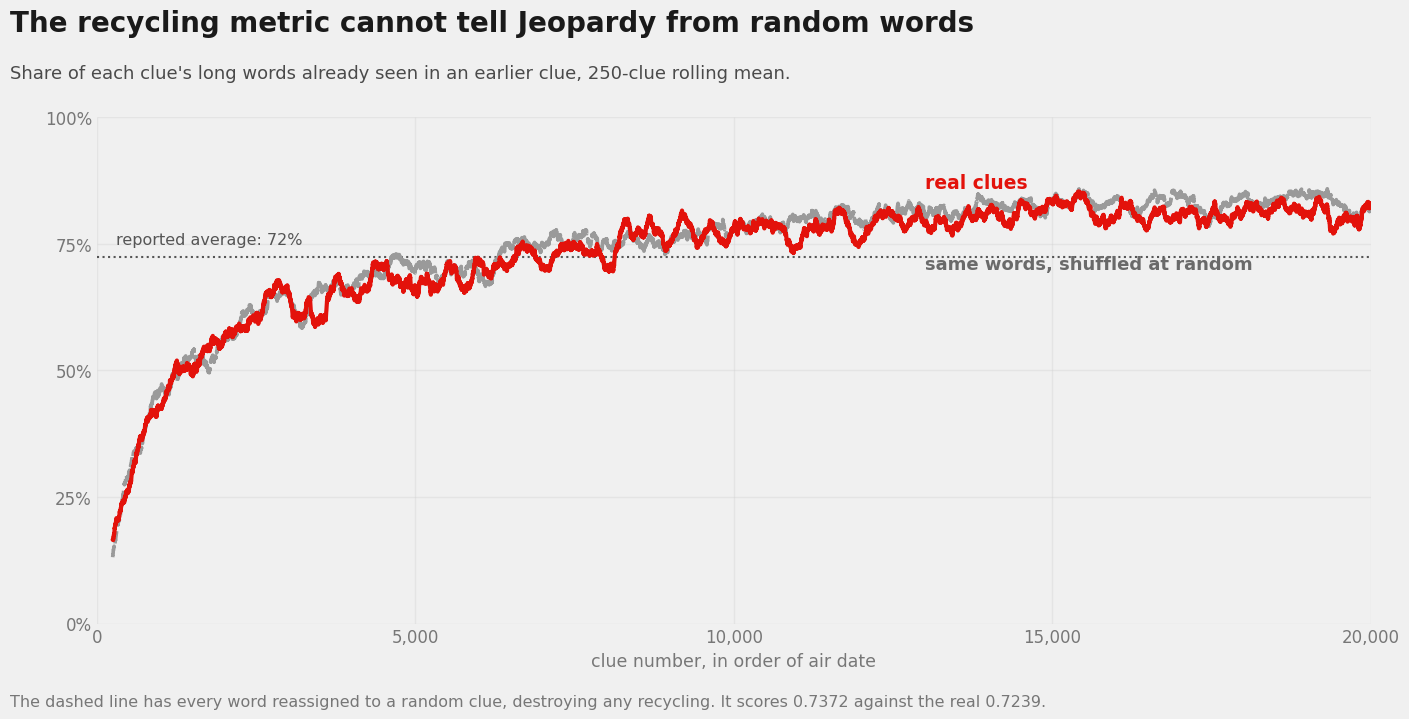

In [8]:
plt.style.use("fivethirtyeight")
C_REAL = "#e3120b"
C_NULL = "#9a9a9a"
C_BLUE = "#2e86ab"

def audit(fig, label):
    """Confirm hand-placed text sits inside the canvas instead of trusting the eye."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bad = []
    for t in fig.texts:
        bb = t.get_window_extent(renderer=r).transformed(fig.transFigure.inverted())
        if bb.y1 > 1.0 or bb.y0 < 0.0 or bb.x1 > 1.0 or bb.x0 < 0.0:
            bad.append((t.get_text()[:40], round(bb.y0, 3), round(bb.y1, 3)))
    print("%s: %d figure texts, %d out of bounds" % (label, len(fig.texts), len(bad)))
    for b in bad:
        print("   OUT OF BOUNDS:", b)
    return len(bad) == 0

# Chart 1: the metric is driven by vocabulary growth, and the null matches it
window = 250
rolling = pd.Series(scores).rolling(window, min_periods=window).mean()
null_scores, _ = mean_overlap(shuffled, track_vocab=True)
rolling_null = pd.Series(null_scores).rolling(window, min_periods=window).mean()

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.plot(rolling.index, rolling.values, color=C_REAL, linewidth=3, zorder=4)
ax.plot(rolling_null.index, rolling_null.values, color=C_NULL, linewidth=2.6,
        linestyle="--", zorder=3)
ax.axhline(scores.mean(), color="#555555", linewidth=1.5, linestyle=":", zorder=2)

ax.set_xlim(0, len(jeopardy))
ax.set_ylim(0, 1.0)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=12)
ax.set_xticks([0, 5000, 10000, 15000, 20000])
ax.set_xticklabels(["0", "5,000", "10,000", "15,000", "20,000"], fontsize=12)
ax.set_xlabel("clue number, in order of air date", fontsize=12.5, color="#777777")
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3)
for s in ax.spines.values():
    s.set_visible(False)

ax.text(13000, 0.86, "real clues", color=C_REAL, fontsize=13.5, weight="bold")
ax.text(13000, 0.70, "same words, shuffled at random", color="#6a6a6a",
        fontsize=13, weight="bold")
ax.text(300, scores.mean() + 0.025, "reported average: 72%", color="#555555", fontsize=11.5)

fig.subplots_adjust(left=0.075, right=0.985, top=0.810, bottom=0.135)
fig.text(0.013, 0.925, "The recycling metric cannot tell Jeopardy from random words",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Share of each clue's long words already seen in an earlier clue, 250-clue rolling mean.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.025,
         "The dashed line has every word reassigned to a random clue, destroying any recycling. It scores 0.7372 against the real 0.7239.",
         fontsize=11.5, color="#777777")
ok1 = audit(fig, "Chart 1")
plt.show()

Chart 2: 3 figure texts, 0 out of bounds

all charts within bounds: True


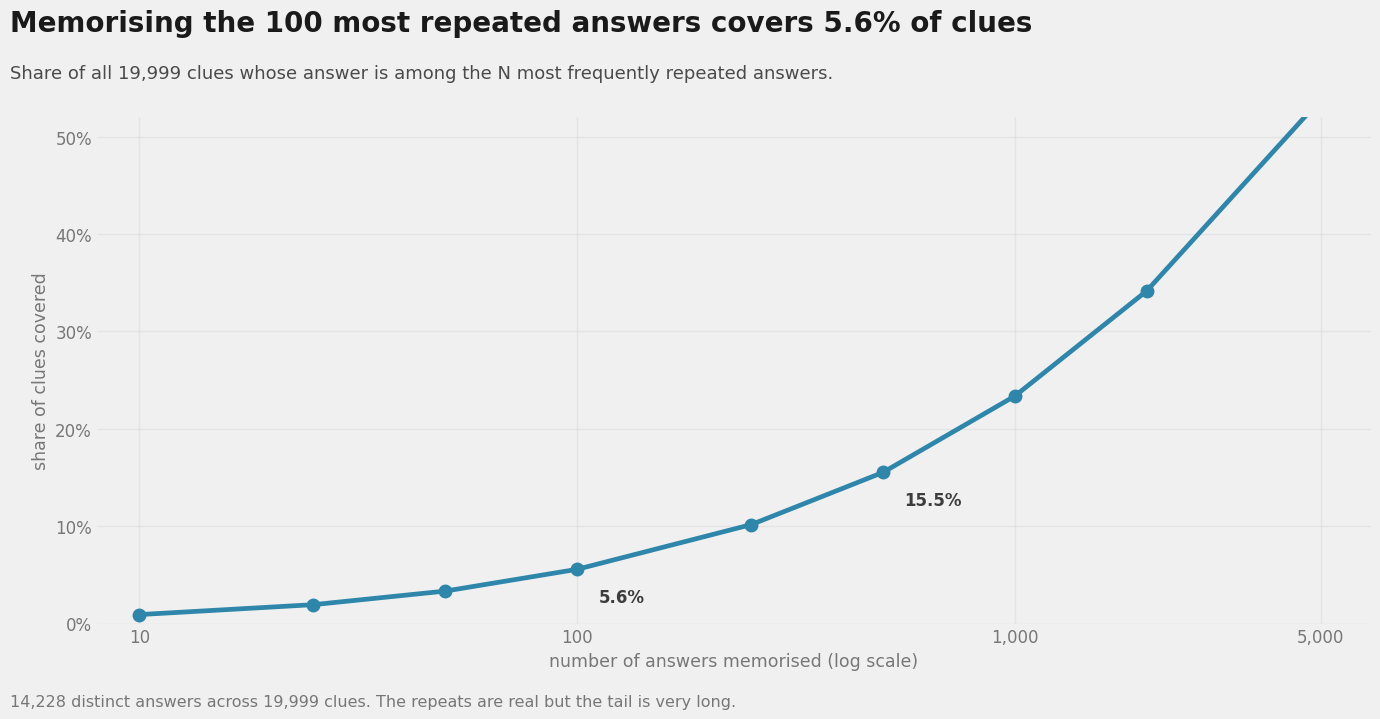

In [9]:
# Chart 2: what you would actually get from memorising answers
ks = [10, 25, 50, 100, 250, 500, 1000, 2000, 5000]
coverage = [100 * sum(n for _, n in answer_counts.most_common(k)) / len(jeopardy) for k in ks]

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.plot(ks, coverage, color=C_BLUE, linewidth=3.4, marker="o", markersize=9, zorder=4)
ax.set_xscale("log")
ax.set_xlim(8, 6500)
ax.set_ylim(0, 52)
ax.set_xticks([10, 100, 1000, 5000])
ax.set_xticklabels(["10", "100", "1,000", "5,000"], fontsize=12)
ax.set_yticks([0, 10, 20, 30, 40, 50])
ax.set_yticklabels(["0%", "10%", "20%", "30%", "40%", "50%"], fontsize=12)
ax.set_xlabel("number of answers memorised (log scale)", fontsize=12.5, color="#777777")
ax.set_ylabel("share of clues covered", fontsize=12.5, color="#777777")
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3)
for s in ax.spines.values():
    s.set_visible(False)

for k, c in zip(ks, coverage):
    if k in (100, 500, 5000):
        ax.annotate("%.1f%%" % c, xy=(k, c), xytext=(k * 1.12, c - 3.4),
                    fontsize=12, weight="bold", color="#3c3c3c")

fig.subplots_adjust(left=0.075, right=0.985, top=0.810, bottom=0.135)
fig.text(0.013, 0.925, "Memorising the 100 most repeated answers covers 5.6% of clues",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Share of all 19,999 clues whose answer is among the N most frequently repeated answers.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.025,
         "14,228 distinct answers across 19,999 clues. The repeats are real but the tail is very long.",
         fontsize=11.5, color="#777777")
ok2 = audit(fig, "Chart 2")
print()
print("all charts within bounds:", bool(ok1 and ok2))
plt.show()

## 8. Conclusions

### Neither of the usual findings holds

**The 70% recycling figure measures nothing.** It reproduces at 0.7239, and then:

| Version of the data | Mean overlap |
|---|---|
| Real clues, in air-date order | 0.7239 |
| **Every word reassigned to a random clue** | **0.7372** |
| Clues in reverse order | 0.7309 |
| Clues in random order | 0.7282 |

Destroying all recycling makes the number go **up**. The metric has no power to detect the thing it is named after. It measures how fast an English vocabulary saturates, which it does quickly: the first 500 clues score 0.213 and the last 500 score 0.810 purely because the vocabulary grows from nothing to 20,249 words as the walk proceeds.

**The chi-squared scan is mostly noise, and its strongest results are HTML.** Across 386 terms appearing in at least 30 clues, 47 clear p < 0.05 where 19 are expected by chance, and only 5 survive Bonferroni correction.

The top two by a wide margin are **archive** (chi-squared 113.7) and **target** (111.1). Neither is a trivia word. The scrape kept the anchor tags for audio and video clues, so `<a href="http://www.j-archive.com/media/...">` appears in 949 clues and `target=` in 752. Normalising turns the markup into words.

The underlying signal is real but misidentified: those tags mark **multimedia clues**, which Jeopardy places disproportionately in high-value positions. The test found a genuine pattern and attributed it to vocabulary.

### What the data actually shows

| Measure | Value |
|---|---|
| Identical questions repeated | 12 of 19,999 (**0.06%**) |
| Clues in any near-duplicate pair (Jaccard >= 0.6) | 368 (**1.84%**) |
| Clues whose answer appears elsewhere | 5,771 (**28.86%**) |
| Distinct answers | 14,228 for 19,999 clues |

**Questions are not recycled. Answers are.** Japan appears as the answer 22 times, India, Australia, China and Canada 19 times each, then Texas, Italy, Chicago. Countries, US states and major cities.

But the tail is long enough to defeat memorisation:

| Answers memorised | Clues covered |
|---|---|
| 100 | 5.6% |
| 500 | 15.5% |

### The practical answer

**Studying past clues in the hope of meeting them again is worthless: 0.06% come back.** Studying the recurring *subjects* is better founded but still thin, since the 100 most repeated answers in 28 years of the show cover one clue in eighteen.

What the data supports is unglamorous. Jeopardy draws on a core of common general knowledge (world geography, US states, major historical figures) and an enormous tail of everything else. Broad knowledge beats a study list, and no analysis of this dataset is going to find a shortcut.

### What I would not claim

- **This is a 19,999-clue sample of roughly 500,000 aired clues.** Recycling that happens on a 20-year cycle would be largely invisible at this sampling density, so "0.06% exact repeats" is a floor on the sample, not a measurement of the show.
- **The 336 episodes are not a random sample** of the 1984-2012 period, and the data is thin for the early years.
- **Jaccard >= 0.6 on long words is my threshold.** Lowering it to 0.5 would admit more pairs and raise the 1.84%; the conclusion is not sensitive to this at any reasonable setting, but the exact number is.
- **Near-duplicate detection used blocking on rare words,** which will miss a rephrased clue sharing no uncommon vocabulary with its twin. It is a lower bound.
- **Answer matching is on exact normalised strings,** so "the US" and "United States" count as different answers. True answer recycling is higher than 28.86%.
- **The $800 cut for "high value" is arbitrary** and ignores that values doubled in 2001, so clue values are not comparable across the span without adjustment.

---

*Dataset: 19,999 Jeopardy clues scraped from J! Archive, via the Dataquest version.*